# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

In [2]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)

def roc_curve(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds


def auc_trapezoid(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def roc_auc(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(5, 1, 1, 13) [[13  1]
 [ 1  5]]
0.8571428571428571 0.8571428571428572 0.8571428571428571


**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


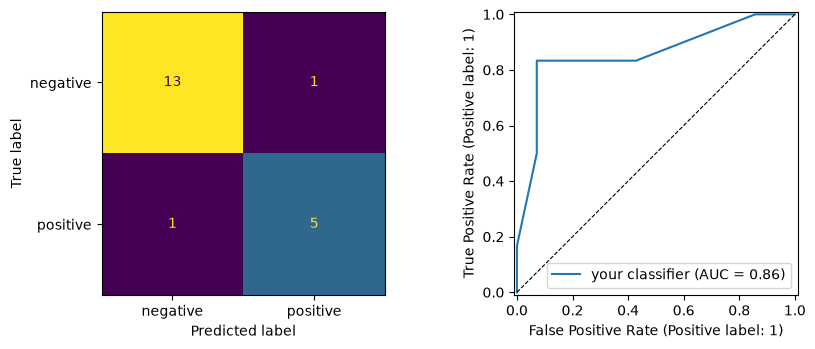

In [3]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?

**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

In [4]:
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)


# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)


def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def mse(predict, target):
    return jnp.mean((predict - target) ** 2)

In [5]:
def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history




In [6]:

def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)
def relu_prime(z):
    return (z > 0).astype(float)

def identity(z):
    return z
def identity_prime(z):
    return np.ones_like(z)
def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)
ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (ReLU, relu_prime),
               "identity": (identity, identity_prime)}
OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}

In [ ]:
d = 8                                  
data = np.load("mnist.npz")            # see Project 2 for where to get it
X_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
X_test = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_train = (data["y_train"] == d).astype(float)
y_test = (data["y_test"] == d).astype(float)

# a) prevalence of d in the test set and the accuracy of the majority rule "never d"
n_test = len(y_test)
prevalence = y_test.mean()
acc_majority = 1 - prevalence
print(f"test set: {n_test} images, {int(y_test.sum())} of them are a {d}")
print(f"prevalence of {d}: {prevalence:.4f}   (training set: {y_train.mean():.4f})")
print(f"accuracy of the majority rule 'never {d}': {acc_majority:.4f}")

test set: 10000 images, 974 of them are a 8
prevalence of 8: 0.0974   (training set: 0.0975)
accuracy of the majority rule 'never 8': 0.9026


In [8]:
# b) logistic regression and one hidden layer, trained with the minibatch SGD of Project 2
models = {}
for name, sizes, act in (("logistic regression", [784, 1], "sigmoid"),
                         ("one hidden layer of 32", [784, 32, 1], "relu")):
    layers = create_layers(sizes, act, np.random.default_rng(2026))
    layers, hist = train(X_train, y_train[:, None], layers, act, "binary", gamma=0.1, epochs=30,
                         batch_size=64, X_test=X_test, y_test=y_test)
    models[name] = {"layers": layers, "act": act, "history": hist,
                    "p_test": np.asarray(predict(X_test, layers, act, "binary"))[:, 0],
                    "n_params": sum(W.size + b.size for W, b in layers)}
    print(f"{name}: {models[name]['n_params']} parameters, final cost {hist['cost'][-1]:.4f}, "
          f"test accuracy {hist['test_accuracy'][-1]:.4f}")

logistic regression: 785 parameters, final cost 0.1131, test accuracy 0.9605


one hidden layer of 32: 25153 parameters, final cost 0.0051, test accuracy 0.9930


--- logistic regression ---
confusion matrix, layout of Eq. (5.67) (rows true 8/not 8, columns predicted 8/not 8):
[[ 730  244]
 [ 151 8875]]
accuracy 0.9605  precision 0.8286  recall 0.7495  F1 0.7871
agrees with scikit-learn: True
errors: 395 vs 974 for the majority rule -> 59.4% of the remaining error removed

--- one hidden layer of 32 ---
confusion matrix, layout of Eq. (5.67) (rows true 8/not 8, columns predicted 8/not 8):
[[ 928   46]
 [  24 9002]]
accuracy 0.9930  precision 0.9748  recall 0.9528  F1 0.9637
agrees with scikit-learn: True
errors: 70 vs 974 for the majority rule -> 92.8% of the remaining error removed



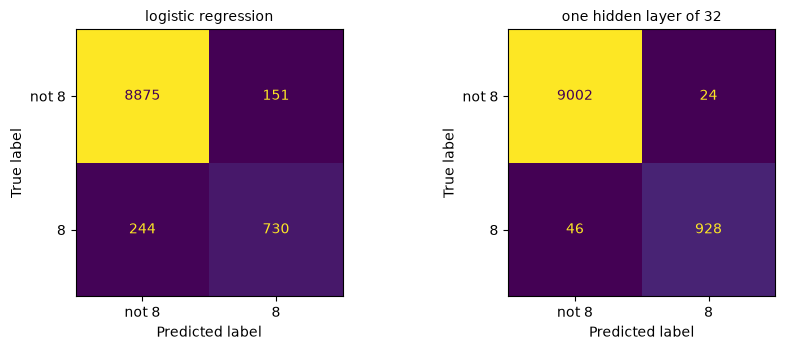

In [9]:
# b) confusion matrices at t = 0.5, our functions checked against scikit-learn
reports = {}
for name in models:
    p = models[name]["p_test"]
    y_pred = p > 0.5
    rep = classification_report(y_test, y_pred)
    reports[name] = rep
    tp, fn, fp, tn = rep["TP"], rep["FN"], rep["FP"], rep["TN"]
    cm_sk = sk_confusion_matrix(y_test, y_pred)               # [[TN, FP], [FN, TP]]
    print(f"--- {name} ---")
    print(f"confusion matrix, layout of Eq. (5.67) (rows true {d}/not {d}, columns predicted {d}/not {d}):")
    print(np.array([[tp, fn], [fp, tn]]))
    print(f"accuracy {rep['accuracy']:.4f}  precision {rep['precision']:.4f}  recall {rep['recall']:.4f}  F1 {rep['f1']:.4f}")
    ok = (np.array_equal(cm_sk, [[tn, fp], [fn, tp]])
          and np.isclose(rep["accuracy"], accuracy_score(y_test, y_pred))
          and np.isclose(rep["precision"], precision_score(y_test, y_pred, zero_division=0))
          and np.isclose(rep["recall"], recall_score(y_test, y_pred))
          and np.isclose(rep["f1"], f1_score(y_test, y_pred)))
    print(f"agrees with scikit-learn: {ok}")
    removed = 1 - (1 - rep["accuracy"]) / (1 - acc_majority)  # fraction of the majority rule's error removed
    print(f"errors: {fn + fp} vs {int(y_test.sum())} for the majority rule -> "
          f"{100 * removed:.1f}% of the remaining error removed\n")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, name in zip(ax, models):
    ConfusionMatrixDisplay(sk_confusion_matrix(y_test, models[name]["p_test"] > 0.5),
                           display_labels=[f"not {d}", f"{d}"]).plot(ax=a, colorbar=False)
    a.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

**Answer b)** Digit $d=8$: the prevalence in the test set is $974/10\,000=9.74\%$, so the majority rule "never an 8" already scores $90.26\%$.

| $t=0.5$ | TP | FN | FP | TN | accuracy | precision | recall | $F_1$ |
|---|---|---|---|---|---|---|---|---|
| logistic regression | 730 | 244 | 151 | 8875 | 0.9605 | 0.8286 | 0.7495 | 0.7871 |
| one hidden layer of 32 (ReLU) | 928 | 46 | 24 | 9002 | 0.9930 | 0.9748 | 0.9528 | 0.9637 |

Our own functions agree exactly with `scikit-learn` for both classifiers. The accuracies (96.1% and 99.3%) both look high, but the matrices show that logistic regression misses a quarter of all eights (244 false negatives, recall 0.75) and that its errors are mostly misses rather than false alarms, while the network finds 95% of the eights with about a sixth as many false alarms. Relative to the 974 errors of the majority rule, logistic regression removes $1-395/974=59\%$ of the remaining error and the network removes $1-70/974=93\%$.

logistic regression: AUC trapezoid 0.96832, ranks 0.96832, sklearn 0.96832; ROC curve: 10001 points, identical to sklearn's: True
one hidden layer of 32: AUC trapezoid 0.99869, ranks 0.99869, sklearn 0.99869; ROC curve: 10001 points, identical to sklearn's: True


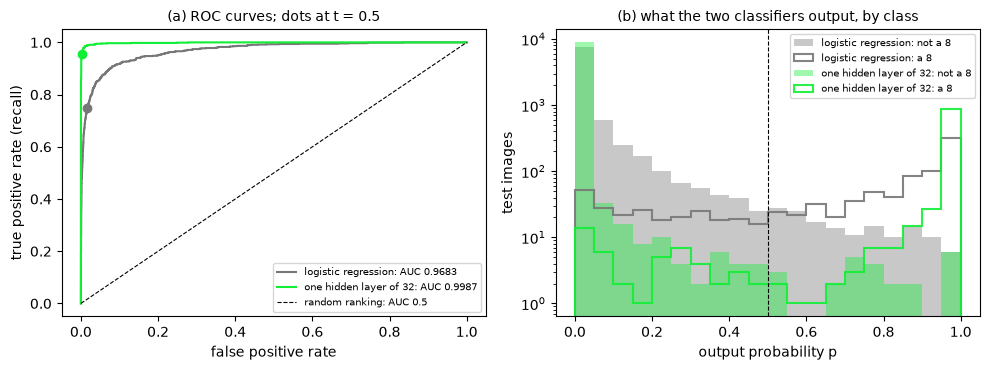

In [10]:
# c) ROC curves, three AUCs each, t = 0.5 marked; histogram of the output probabilities by class
GREY="#777777"
GREEN="#10EF35"
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for name, col in zip(models, (GREY, GREEN)):
    p = models[name]["p_test"]
    fpr, tpr, thr = roc_curve(y_test, p)
    auc_t, auc_r, auc_s = auc_trapezoid(fpr, tpr), roc_auc(y_test, p), skm.roc_auc_score(y_test, p)
    fpr_s, tpr_s, _ = skm.roc_curve(y_test, p, drop_intermediate=False)   # sklearn drops collinear points by default
    print(f"{name}: AUC trapezoid {auc_t:.5f}, ranks {auc_r:.5f}, sklearn {auc_s:.5f}; "
          f"ROC curve: {len(fpr)} points, identical to sklearn's: {np.allclose(fpr, fpr_s) and np.allclose(tpr, tpr_s)}")
    ax[0].plot(fpr, tpr, color=col, lw=1.5, label=f"{name}: AUC {auc_r:.4f}")
    k = np.searchsorted(-thr, -0.5)
    ax[0].plot(fpr[min(k, len(fpr) - 1)], tpr[min(k, len(tpr) - 1)], "o", color=col)
    bins = np.linspace(0, 1, 21)
    ax[1].hist(p[y_test == 0], bins=bins, color=col, alpha=0.4, label=f"{name}: not a {d}")
    ax[1].hist(p[y_test == 1], bins=bins, color=col, alpha=0.9, histtype="step", lw=1.5, label=f"{name}: a {d}")

ax[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="random ranking: AUC 0.5")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate (recall)"); ax[0].legend(fontsize=7)
ax[0].set_title("(a) ROC curves; dots at t = 0.5", fontsize=10)
ax[1].axvline(0.5, color="k", ls="--", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlabel("output probability p"); ax[1].set_ylabel("test images"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) what the two classifiers output, by class", fontsize=10)
plt.tight_layout(); plt.show()

**Answer c)** All three AUCs agree to every printed digit: $0.96832$ for logistic regression and $0.99869$ for the network (our ROC curves are also identical to `sklearn`'s with `drop_intermediate=False`).

*Where the errors live:* the network pushes almost all images to the two ends of $[0,1]$, so only a handful of test images (on the log axis) lie near $t=0.5$. Its few errors are mostly *confident* ones, eights at $p\approx0$ and non-eights at $p\approx1$, which no choice of threshold would fix. For logistic regression the non-eights have a long tail from $p\approx0.05$ up past $0.5$ (the 151 false positives), and the eights are spread almost evenly over the whole interval, with about 50 of them at $p<0.05$. The linear model is uncertain about a large fraction of the eights, so a single linear boundary does not separate them well from the other digits.

*What the AUC difference adds:* a confusion matrix is one point on the ROC curve, and changing the threshold only moves along that curve. For logistic regression a lower threshold would raise recall at the cost of more false positives, but its whole curve lies below the network's. In ranking terms, a random 8 is scored below a random non-8 in $3.2\%$ of the pairs for logistic regression and in only $0.13\%$ for the network, about 25 times fewer. The network is therefore better at *ranking* the images, not just better calibrated around $0.5$. That is independent of the threshold and of the class balance, and the matrices at $0.5$ cannot show it.

In [11]:
# d) standard errors, Eq. (2.24): sqrt(p (1 - p) / n), n = all test images for the accuracy,
#    n = the positive test images for the recall
n_pos = int(y_test.sum())
for name, rep in reports.items():
    se_acc = np.sqrt(rep["accuracy"] * (1 - rep["accuracy"]) / n_test)
    se_rec = np.sqrt(rep["recall"] * (1 - rep["recall"]) / n_pos)
    print(f"{name:24s} accuracy {rep['accuracy']:.4f} +- {se_acc:.4f}   recall {rep['recall']:.4f} +- {se_rec:.4f}")

r_lr, r_nn = reports["logistic regression"], reports["one hidden layer of 32"]
for key, n in (("accuracy", n_test), ("recall", n_pos)):
    diff = r_nn[key] - r_lr[key]
    se_diff = np.sqrt(sum(r[key] * (1 - r[key]) / n for r in (r_lr, r_nn)))
    print(f"difference in {key}: {diff:.4f} +- {se_diff:.4f}  ({diff / se_diff:.1f} standard errors)")

logistic regression      accuracy 0.9605 +- 0.0019   recall 0.7495 +- 0.0139
one hidden layer of 32   accuracy 0.9930 +- 0.0008   recall 0.9528 +- 0.0068
difference in accuracy: 0.0325 +- 0.0021  (15.3 standard errors)
difference in recall: 0.2033 +- 0.0155  (13.2 standard errors)


**Answer d)** With $\mathrm{SE}=\sqrt{\hat p(1-\hat p)/n}$, using $n=10\,000$ for the accuracy and $n=n_+=974$ for the recall:

| | accuracy | recall |
|---|---|---|
| logistic regression | $0.9605\pm0.0019$ | $0.750\pm0.014$ |
| one hidden layer of 32 | $0.9930\pm0.0008$ | $0.953\pm0.007$ |

The recall uses only the 974 eights, so its standard error is about 7–8 times larger than that of the accuracy. The differences are $0.0325\pm0.0021$ in accuracy and $0.203\pm0.016$ in recall, i.e. 15 and 13 standard errors. That is clearly significant. The two classifiers are evaluated on the *same* test images, so the errors are positively correlated and the standard error of the difference computed as if they were independent is, if anything, too large. A paired test (e.g. McNemar on the images where the two classifiers disagree) would give an even clearer result. What these error bars do not include is the variation between training runs (seed, minibatch order). With a difference this large, it would not change the conclusion.

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [12]:
...

Ellipsis

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

Tools used : (Claude opus 5.5)

Used for debugging in exercise 2, and filling the data tables